# Estimate power from sample size, AF, effect and effect SD

## Import libraries

In [131]:
import pandas as pd
import numpy as np
import os
import math
import seaborn as sns
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.power import GofChisquarePower

## Important values

In [132]:
os.listdir('./data/genotype')

['0_0_115_0_maf_0.01_0.01.pkl',
 '21_9_120_21_maf_0.024_0.025.pkl',
 '124_0_118_124_maf_0.4_0.41.pkl',
 '107_3_80_107_maf_0.3_0.31.pkl',
 '48_9_120_48_maf_0.068_0.07.pkl',
 '42_9_80_42_maf_0.055_0.057.pkl',
 '39_9_103_39_maf_0.05_0.051.pkl',
 '87_0_110_87_maf_0.2_0.2.pkl',
 '26_9_120_26_maf_0.03_0.031.pkl',
 '16_9_92_16_maf_0.02_0.021.pkl',
 '33_9_89_33_maf_0.04_0.041.pkl',
 '57_7_120_57_maf_0.091_0.094.pkl',
 '44_9_114_44_maf_0.059_0.061.pkl',
 '36_9_80_36_maf_0.044_0.046.pkl',
 '53_1_116_53_maf_0.08_0.083.pkl',
 '138_9_80_138_maf_0.49_0.49.pkl',
 '75_4_91_75_maf_0.15_0.15.pkl',
 '30_9_80_30_maf_0.035_0.037.pkl',
 '60_2_120_60_maf_0.1_0.1.pkl',
 '8_9_120_8_maf_0.014_0.015.pkl',
 '97_4_80_97_maf_0.25_0.25.pkl']

In [133]:
wanted_maf = '0.3_0.31'

ratio = 14
snp_num = 0
true_mean = 0
true_effect = 5
true_sd = true_effect*ratio
iteration = 200

min_power = 0.9

## Load data

### Humans

In [134]:
humans = pd.read_csv('./data/phenotype/all.panel',delim_whitespace=True)
humans

,sample,sample.1,pop,super_pop,gender
0,HG00096,HG00096,GBR,EUR,male
1,HG00097,HG00097,GBR,EUR,female
2,HG00099,HG00099,GBR,EUR,female
3,HG00100,HG00100,GBR,EUR,female
4,HG00101,HG00101,GBR,EUR,male
...,...,...,...,...,...
2499,NA21137,NA21137,GIH,SAS,female
2500,NA21141,NA21141,GIH,SAS,female
2501,NA21142,NA21142,GIH,SAS,female
2502,NA21143,NA21143,GIH,SAS,female


### Genotype

In [135]:
snps = [f for f in os.listdir('./data/genotype') if f.split("_maf_")[1].split('.pkl')[0] == wanted_maf]
for snp in snps:
    maf = snp.split("_maf_")[1].split('.pkl')[0]
    print(maf)
    path_snp = f"./data/genotype/{snp}"
    print(path_snp)
    geno = pd.read_pickle(path_snp)

0.3_0.31
./data/genotype/107_3_80_107_maf_0.3_0.31.pkl


### Calculating exact MAF

In [136]:
geno[geno.columns[snp_num]].value_counts()
num_maj = geno[geno.columns[snp_num]].value_counts()[1]
num_het = geno[geno.columns[snp_num]].value_counts()[0]
try:
    num_min = geno[geno.columns[snp_num]].value_counts()[-1]
except Exception as e:
    num_min = 0
total_humans = num_maj + num_het + num_min
maf = (num_min*2 + num_het)/(total_humans*2)
maf

0.30451277955271566

### Inputing exact values

### Loop for nul hypothesis

In [137]:
estimated_effect_nul = []
estimated_intercept_nul = []
SE_nul = []
p_nul = []

i = 0
for i in range(iteration):
    mean_min = true_mean
    mean_het = true_mean
    mean_maj = true_mean
    sigma_min = true_sd
    sigma_het = true_sd
    sigma_maj = true_sd
    pheno = []
    for var in list(geno[geno.columns[snp_num]]):
        if var == 1:
            pheno.append(np.random.normal(mean_maj, sigma_maj, 1)[0])
        elif var == 0:
            pheno.append(np.random.normal(mean_het, sigma_het, 1)[0])
        else:
            pheno.append(np.random.normal(mean_min, sigma_min, 1)[0])
    df_pheno = pd.DataFrame(data = {"geno": list(geno[geno.columns[snp_num]]), "pheno_null": pheno})

    X = df_pheno[['geno']]
    y = df_pheno[['pheno_null']]
    reg = LinearRegression().fit(X, y)
    estimated_effect_nul.append(reg.coef_[0][0])
    estimated_intercept_nul.append(reg.intercept_[0])
    
    # Calculating p values and standard error
    N = len(X)
    p = len(X.columns) + 1
    X_with_intercept = np.empty(shape=(N, p), dtype=float)
    X_with_intercept[:, 0] = 1
    X_with_intercept[:, 1:p] = X.values
    
    params = np.append(reg.intercept_,reg.coef_)
    predictions = reg.predict(X)
    new_y = (y-predictions)**2
    newX = pd.DataFrame({"Constant":np.ones(len(X))}).join(pd.DataFrame(list(X['geno'])))
    MSE = (sum(list(new_y['pheno_null'])))/(len(newX)-len(newX.columns))
    
    var_b = MSE*(np.linalg.inv(np.dot(newX.T,newX)).diagonal())
    

    sd_b = np.sqrt(var_b)
    ts_b = params/ sd_b
    
    p_values =[2*(1-stats.t.cdf(np.abs(i),(len(newX)-len(newX.columns)))) for i in ts_b]
    
    SE_nul.append(sd_b[1])
    p_nul.append(p_values[1])

### Loop for alternate hypothesis

In [138]:
estimated_effect_alt = []
estimated_intercept_alt = []
SE_alt = []
p_alt = []

for i in range(iteration):
    mean_min = true_mean - true_effect
    mean_het = true_mean
    mean_maj = true_mean + true_effect
    sigma_min = true_sd
    sigma_het = true_sd
    sigma_maj = true_sd
    pheno = []
    for var in list(geno[geno.columns[snp_num]]):
        if var == 1:
            pheno.append(np.random.normal(mean_maj, sigma_maj, 1)[0])
        elif var == 0:
            pheno.append(np.random.normal(mean_het, sigma_het, 1)[0])
        else:
            pheno.append(np.random.normal(mean_min, sigma_min, 1)[0])
    df_pheno = pd.DataFrame(data = {"geno": list(geno[geno.columns[snp_num]]), "pheno": pheno})

    X = df_pheno[['geno']]
    y = df_pheno[['pheno']]
    reg = LinearRegression().fit(X, y)
    estimated_effect_alt.append(reg.coef_[0][0])
    estimated_intercept_alt.append(reg.intercept_[0])
    
    # Calculating p values and standard error
    N = len(X)
    p = len(X.columns) + 1
    X_with_intercept = np.empty(shape=(N, p), dtype=float)
    X_with_intercept[:, 0] = 1
    X_with_intercept[:, 1:p] = X.values
    
    params = np.append(reg.intercept_,reg.coef_)
    predictions = reg.predict(X)
    new_y = (y-predictions)**2
    newX = pd.DataFrame({"Constant":np.ones(len(X))}).join(pd.DataFrame(list(X['geno'])))
    MSE = (sum(list(new_y['pheno'])))/(len(newX)-len(newX.columns))
    
    var_b = MSE*(np.linalg.inv(np.dot(newX.T,newX)).diagonal())
    sd_b = np.sqrt(var_b)
    ts_b = params/ sd_b
    
    p_values =[2*(1-stats.t.cdf(np.abs(i),(len(newX)-len(newX.columns)))) for i in ts_b]
    SE_alt.append(sd_b[1])
    p_alt.append(p_values[1])

### Create distribution plot

In [139]:
labels = ['nul hypothesis']*len(estimated_effect_nul) + ['alternate hypothesis'] * len(estimated_effect_alt)
dis = pd.DataFrame(data={"Z": list(estimated_effect_nul)+list(estimated_effect_alt), 'labels': labels})

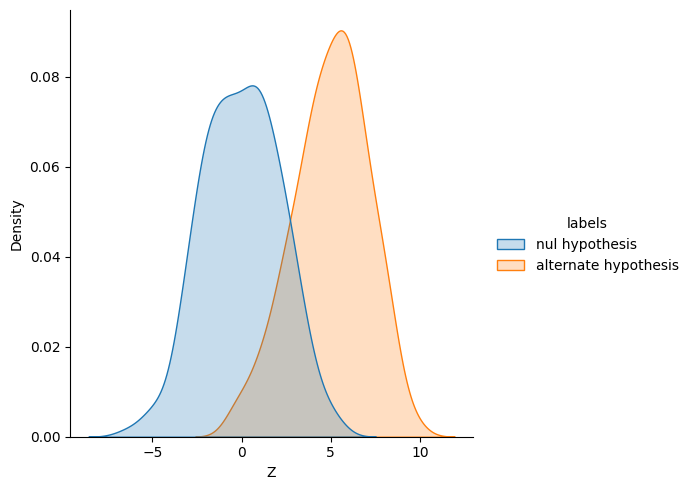

In [140]:
sns_plot = sns.displot(dis, x="Z", hue='labels',kind="kde",fill=True)
plt.show()

In [141]:
dis_only_alt = pd.DataFrame(data={"Z": list(estimated_effect_alt)})

In [142]:
dis['Z'] = dis['Z']/(SE_nul+SE_alt)

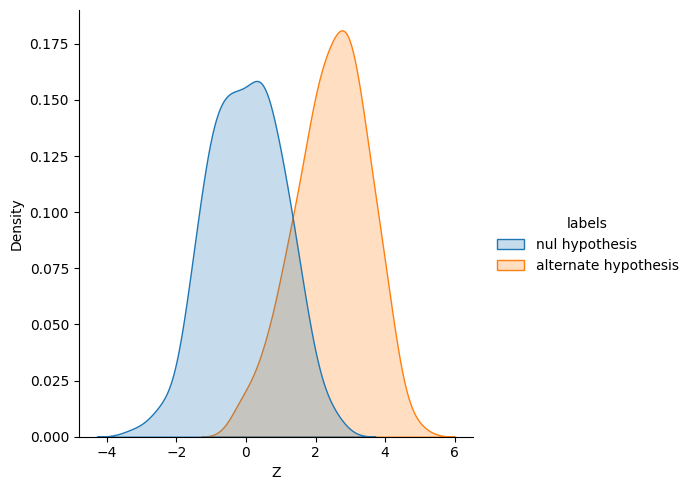

In [143]:
sns_plot = sns.displot(dis, x="Z", hue='labels',kind="kde",fill=True)
plt.show()

In [144]:
dis['Z2'] = dis['Z']**2

In [145]:
cuttof = stats.chi2.ppf(min_power, df=1)
cuttof

2.705543454095404

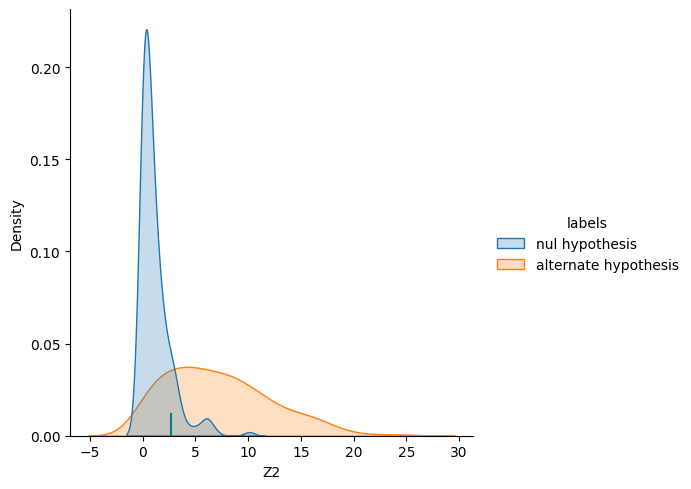

In [146]:
sns_plot = sns.displot(dis, x="Z2", hue='labels',kind="kde",fill=True)
plt.axvline(cuttof, 0,0.05, color = '#008080')
plt.show()

In [147]:
stats.chi2.ppf(0.99, df=1)

6.6348966010212145

In [148]:
dis_only_alt['Z2'] = (dis_only_alt['Z']/SE_alt)**2

In [149]:
omega = 0
for val in list(dis_only_alt['Z2']):
    if val > cuttof:
        omega += 1
    else:
        pass
power = omega/len(list(dis_only_alt['Z2']))
print(round(power*100,8))

78.5


In [150]:
power

0.785